# The scorecard and the vintages

The probability of default scorecard's benchmark table, and cumulative default by vintage, from the committed results.

> Harborline Bank is fictional. This is a demonstration on generated data and public datasets; no real customer, account or transaction of any real institution appears here.
>
> Nothing here is a credit decision, a fraud determination, a suspicious activity finding or investment advice.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
from ledger_core.manifest import Manifest

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
m = Manifest.load(ROOT / "results" / "manifest.json")
plt.rcParams["figure.figsize"] = (9, 4)

In [2]:
bench = m.tables["models.pd_scorecard.benchmark"]
pl.DataFrame(bench.rows, schema=bench.columns, orient="row")

Model,AUROC,Gini,Brier,ECE
str,f64,f64,f64,f64
"""This model""",0.661848,0.323697,0.062563,0.028593
"""Base rate""",0.5,0.0,0.064136,0.030696
"""Logistic on raw characteristic…",0.668184,0.336368,0.06244,0.02853
"""Challenger (GBM)""",0.667199,0.334397,0.06239,0.02791


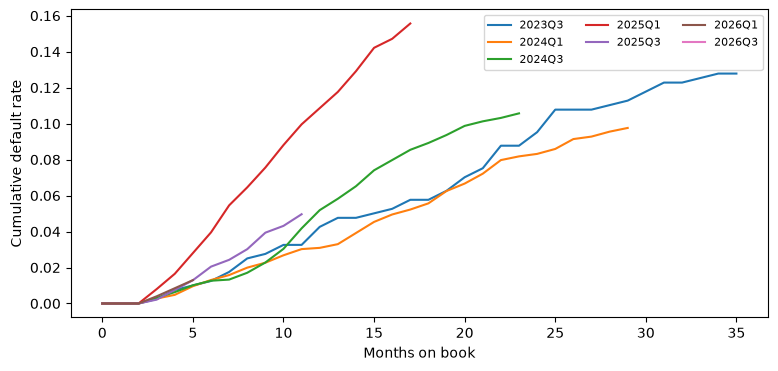

In [3]:
v = pl.read_parquet(ROOT / "results" / "f02" / "vintages.parquet")
fig, ax = plt.subplots()
for vintage in sorted(v["vintage"].unique().to_list())[::2]:
    part = v.filter(pl.col("vintage") == vintage)
    ax.plot(part["months_on_book"], part["cumulative_default_rate"], label=vintage)
ax.set_xlabel("Months on book")
ax.set_ylabel("Cumulative default rate")
ax.legend(ncol=3, fontsize=8)
plt.show()

In [4]:
print("Loose vintages:", m.text("policy.loose_vintages"))
print("Twelve months on book, loose:", m.text("f02.loose_12mob"), " before them:", m.text("f02.prior_12mob"))

Loose vintages: 2024Q4 and 2025Q1
Twelve months on book, loose: 10.4%  before them: 4.0%
